In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
DecodeLabs_df = pd.read_excel(
    r"C:\Users\segun\OneDrive\Documents\Co-Harvester\Wisdom Class\Wisdom Python\Decode Lab\Decode_Lab.xlsx"
)

DecodeLabs_df.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [3]:
# Checking for null values
DecodeLabs_df.isnull().sum()

OrderID              0
Date                 0
CustomerID           0
Product              0
Quantity             0
UnitPrice            0
ShippingAddress      0
PaymentMethod        0
OrderStatus          0
TrackingNumber       0
ItemsInCart          0
CouponCode         309
ReferralSource       0
TotalPrice           0
dtype: int64

In [4]:
# Checking the shape of the dataframe
DecodeLabs_df.shape

(1200, 14)

In [5]:
# checking for number of unique values in the target
DecodeLabs_df.nunique()

OrderID            1200
Date                671
CustomerID         1189
Product               7
Quantity              5
UnitPrice          1193
ShippingAddress     655
PaymentMethod         5
OrderStatus           5
TrackingNumber     1200
ItemsInCart          10
CouponCode            3
ReferralSource        5
TotalPrice         1195
dtype: int64

In [6]:
# Count duplicate rows
print("Number of duplicate rows:", DecodeLabs_df.duplicated().sum())

Number of duplicate rows: 0


In [7]:
# checking for the stastistics
DecodeLabs_df.describe()

,Date,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200,1200.000000,1200.000000,1200.000000,1200.000000
mean,2024-03-22 16:58:48,2.945833,356.412750,5.485000,1053.968300
min,2023-01-01 00:00:00,1.000000,11.390000,1.000000,11.390000
25%,2023-08-03 18:00:00,2.000000,186.062500,4.000000,410.520000
50%,2024-03-23 00:00:00,3.000000,364.210000,5.000000,823.615000
75%,2024-11-08 12:00:00,4.000000,521.570000,7.000000,1578.475000
max,2025-06-30 00:00:00,5.000000,699.930000,10.000000,3456.400000
std,NaN,1.407557,197.177146,2.281983,819.856558


In [8]:
numeric_df = DecodeLabs_df.select_dtypes(include='number')
numeric_df.agg(['mean', 'median', 'std', 'min', 'max'])

,Quantity,UnitPrice,ItemsInCart,TotalPrice
mean,2.945833,356.412750,5.485000,1053.968300
median,3.000000,364.210000,5.000000,823.615000
std,1.407557,197.177146,2.281983,819.856558
min,1.000000,11.390000,1.000000,11.390000
max,5.000000,699.930000,10.000000,3456.400000


In [9]:
DecodeLabs_df.dtypes

OrderID                    object
Date               datetime64[ns]
CustomerID                 object
Product                    object
Quantity                    int64
UnitPrice                 float64
ShippingAddress            object
PaymentMethod              object
OrderStatus                object
TrackingNumber             object
ItemsInCart                 int64
CouponCode                 object
ReferralSource             object
TotalPrice                float64
dtype: object

In [10]:
DecodeLabs_df.columns

Index(['OrderID', 'Date', 'CustomerID', 'Product', 'Quantity', 'UnitPrice',
       'ShippingAddress', 'PaymentMethod', 'OrderStatus', 'TrackingNumber',
       'ItemsInCart', 'CouponCode', 'ReferralSource', 'TotalPrice'],
      dtype='object')

## Correlation heatmap
#### This helps identify variables that move together.

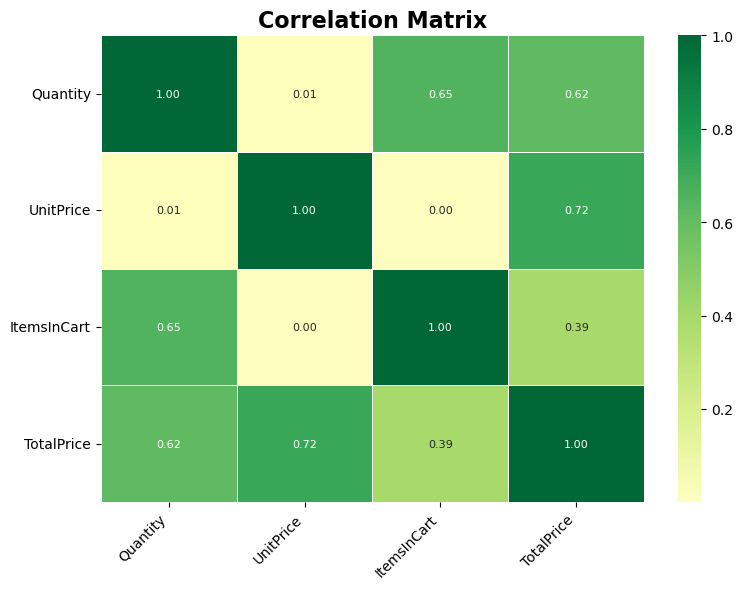

In [11]:
# Keep only numeric columns
numeric_df = DecodeLabs_df.select_dtypes(include=['int64', 'float64'])

# Correlation matrix
corr_matrix = numeric_df.corr(method='pearson')

# Plot heatmap
plt.figure(figsize=(8,6))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    center=0,
    linewidths=0.5,
    annot_kws={'size':8}
)

plt.title('Correlation Matrix', fontsize=16, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Trend analysis of Decodelabs Revenue

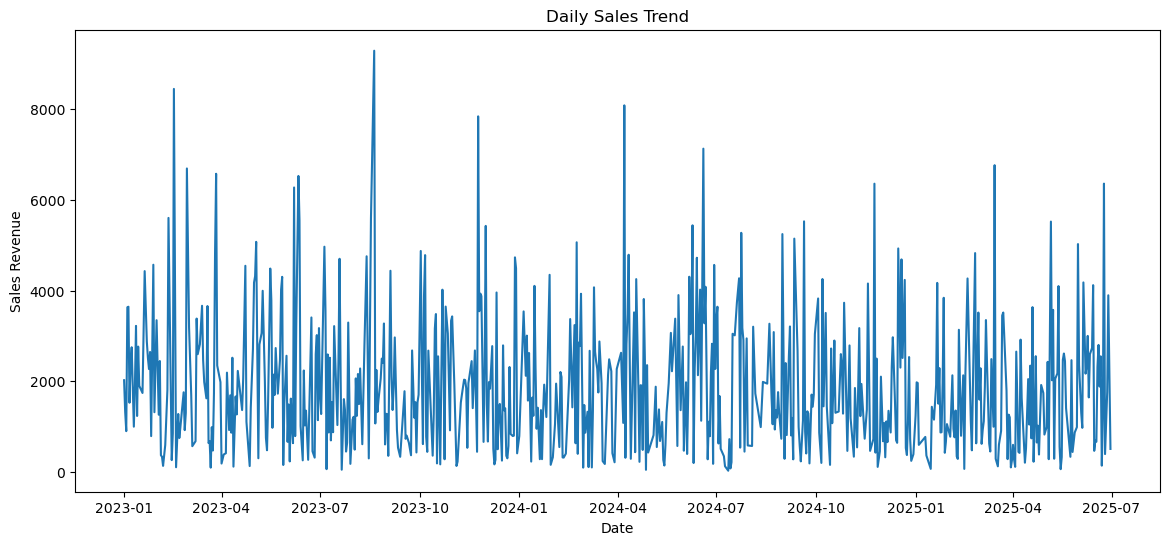

In [12]:
daily_sales = DecodeLabs_df.groupby(
    DecodeLabs_df['Date'].dt.date
)['TotalPrice'].sum()

daily_sales.plot(figsize=(14, 6))

plt.title('Daily Sales Trend')
plt.xlabel('Date')
plt.ylabel('Sales Revenue')
plt.show()

### Decodelabs Monthly Revenue Trend

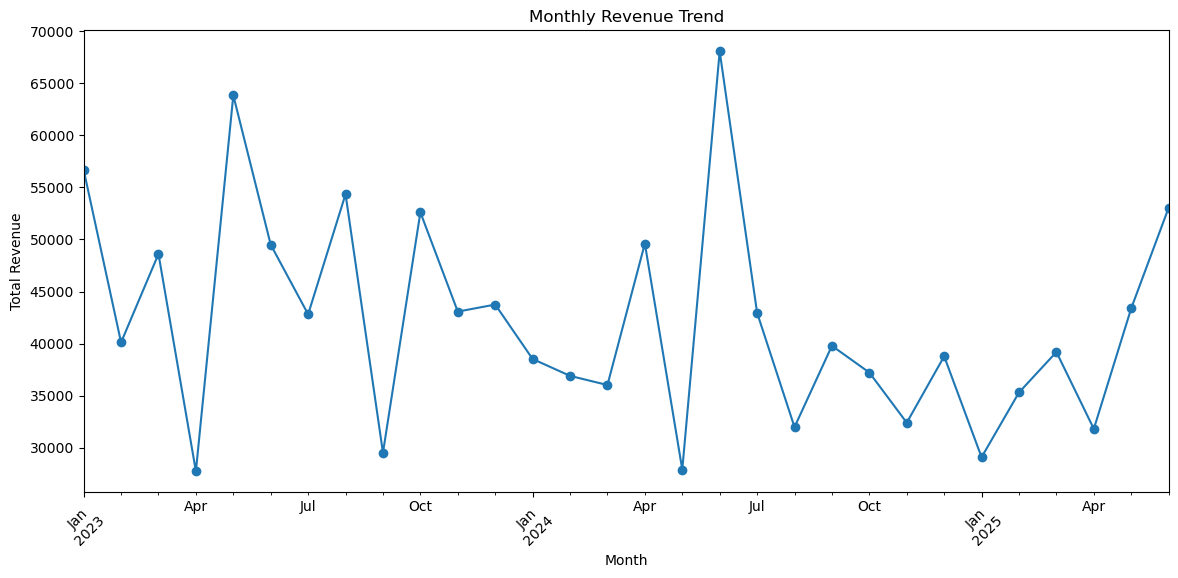

In [13]:
monthly_revenue = DecodeLabs_df.groupby(
    DecodeLabs_df['Date'].dt.to_period('M')
)['TotalPrice'].sum()

monthly_revenue.plot(
    figsize=(14, 6),
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.show()

## Analysis of Count of Products

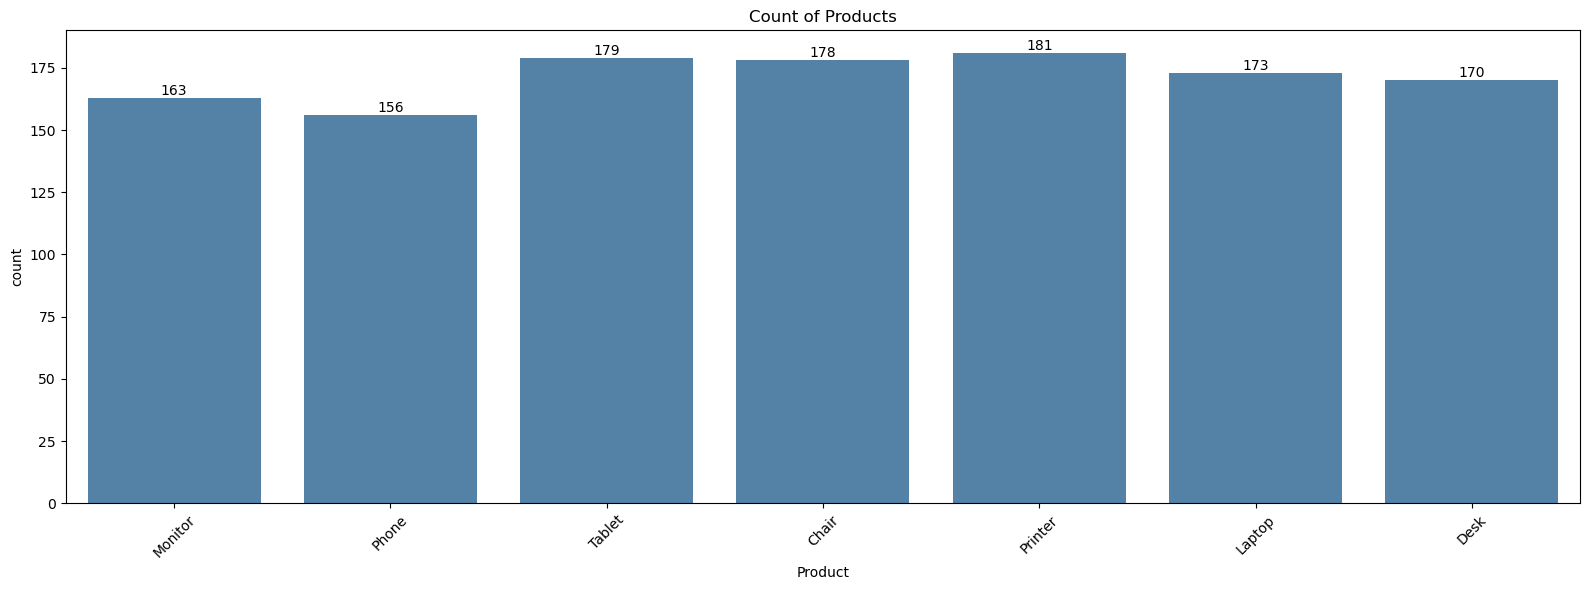

In [14]:
plt.figure(figsize=(16,6))

ax = sns.countplot(
    data=DecodeLabs_df,
    x='Product',
    color='steelblue'
)

ax.bar_label(ax.containers[0])

plt.title('Count of Products')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Analysis of Monthly Quantity of Product Sold

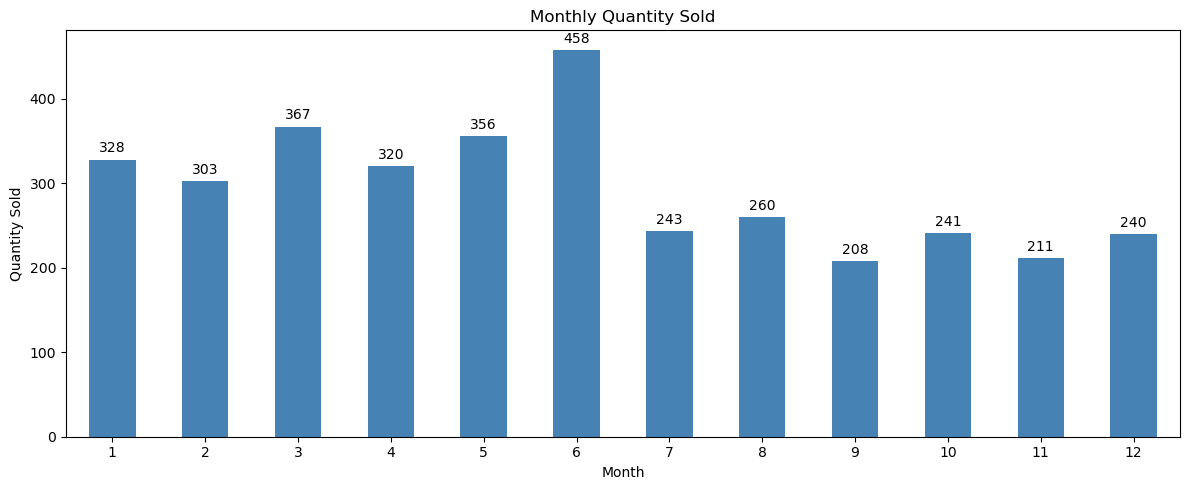

In [15]:
monthly_quantity = DecodeLabs_df.groupby(
    DecodeLabs_df['Date'].dt.month
)['Quantity'].sum()

ax = monthly_quantity.plot(
    kind='bar',
    figsize=(12, 5),
    color='steelblue'
)

# Add data labels
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3)

plt.title('Monthly Quantity Sold')
plt.xlabel('Month')
plt.ylabel('Quantity Sold')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Average Revenue by Product

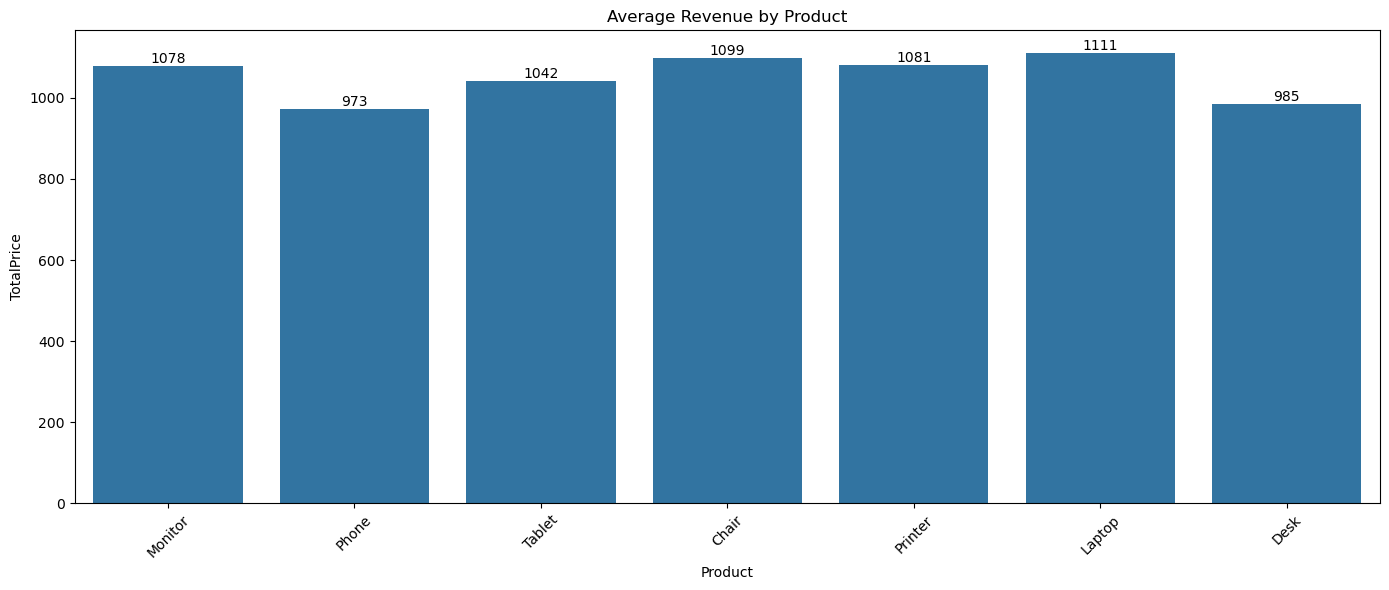

In [16]:
plt.figure(figsize=(14, 6))

ax = sns.barplot(
    data=DecodeLabs_df,
    x='Product',
    y='TotalPrice',
    estimator='mean',
    errorbar=None
)

ax.bar_label(ax.containers[0], fmt='%.0f')

plt.title('Average Revenue by Product')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Analysis of Revenue by Product

In [17]:
DecodeLabs_df.groupby('Product')['TotalPrice'].sum().sort_values(
    ascending=False
)

Product
Chair      195620.11
Printer    195612.61
Laptop     192126.56
Tablet     186568.95
Monitor    175651.41
Desk       167459.93
Phone      151722.39
Name: TotalPrice, dtype: float64

In [18]:
pd.pivot_table(
    DecodeLabs_df,
    index='Product',
    values=['Quantity', 'TotalPrice'],
    aggfunc={
        'Quantity': 'sum',
        'TotalPrice': 'sum'
    }
)

,Quantity,TotalPrice
Product,,
Chair,562,195620.11
Desk,508,167459.93
Laptop,535,192126.56
Monitor,480,175651.41
Phone,411,151722.39
Printer,542,195612.61
Tablet,497,186568.95


## Summary of Revenue by Product

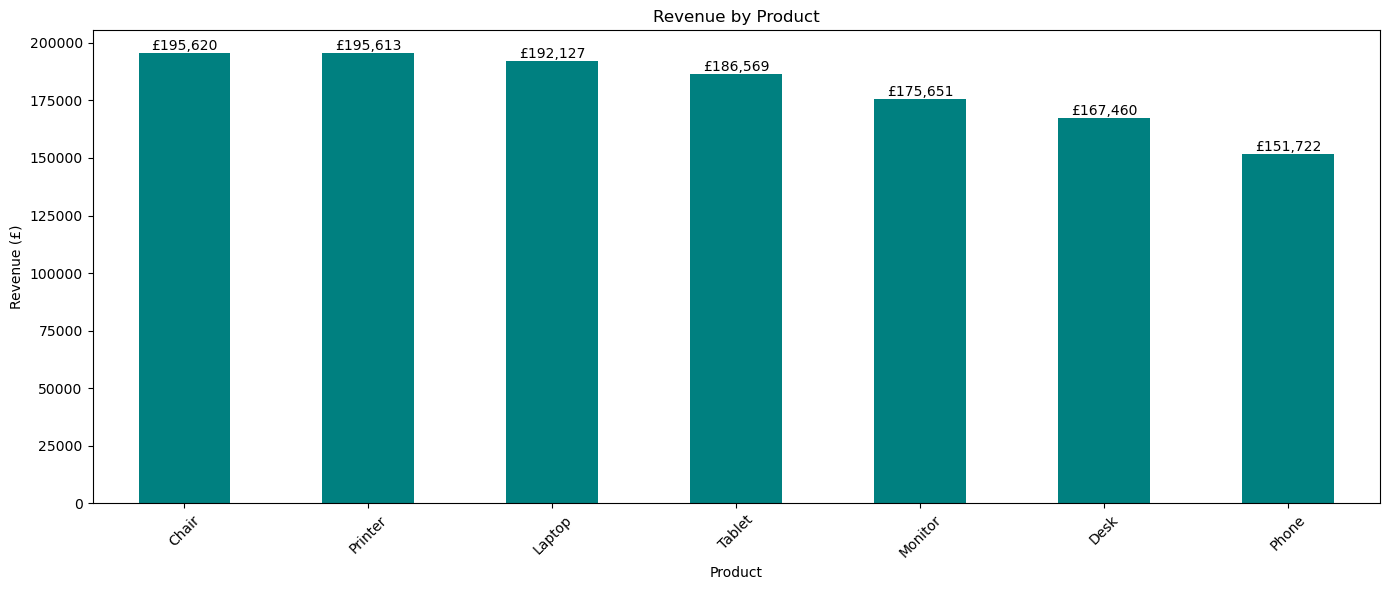

In [19]:
product_revenue = DecodeLabs_df.groupby('Product')['TotalPrice'].sum().sort_values(
    ascending=False
)

ax = product_revenue.plot(
    kind='bar',
    figsize=(14,6),
    color='teal'
)

ax.bar_label(ax.containers[0], fmt='£{:,.0f}')

plt.title('Revenue by Product')
plt.xlabel('Product')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Product Statistics

In [20]:
product_analysis = DecodeLabs_df.groupby('Product').agg(
    Total_Quantity=('Quantity', 'sum'),
    Average_Quantity=('Quantity', 'mean'),
    Total_Revenue=('TotalPrice', 'sum'),
    Average_Revenue=('TotalPrice', 'mean'),
    Average_UnitPrice=('UnitPrice', 'mean'),
    Transaction_Count=('Product', 'count')
).sort_values(
    by='Total_Revenue',
    ascending=False
)

print(product_analysis)

         Total_Quantity  Average_Quantity  Total_Revenue  Average_Revenue  \
Product                                                                     
Chair               562          3.157303      195620.11      1098.989382   
Printer             542          2.994475      195612.61      1080.732652   
Laptop              535          3.092486      192126.56      1110.558150   
Tablet              497          2.776536      186568.95      1042.284637   
Monitor             480          2.944785      175651.41      1077.616012   
Desk                508          2.988235      167459.93       985.058412   
Phone               411          2.634615      151722.39       972.579423   

         Average_UnitPrice  Transaction_Count  
Product                                        
Chair           355.660281                178  
Printer         351.714917                181  
Laptop          357.707052                173  
Tablet          367.679106                179  
Monitor         35

# Overall Business Performance

In [21]:
print('Total Revenue:', DecodeLabs_df['TotalPrice'].sum())

print('Average Revenue:', DecodeLabs_df['TotalPrice'].mean())

print('Total Quantity Sold:', DecodeLabs_df['Quantity'].sum())

print('Total Transactions:', len(DecodeLabs_df))

print('Number of Unique Products:', DecodeLabs_df['Product'].nunique())

Total Revenue: 1264761.96
Average Revenue: 1053.9683
Total Quantity Sold: 3535
Total Transactions: 1200
Number of Unique Products: 7


## Rolling Revenue

In [22]:
DecodeLabs_df['TotalPrice'] = pd.to_numeric(DecodeLabs_df['TotalPrice'], errors='coerce').fillna(0)
DecodeLabs_df = DecodeLabs_df.sort_values('Date').reset_index(drop=True)
DecodeLabs_df['Cumulative_Revenue'] = DecodeLabs_df['TotalPrice'].cumsum()

DecodeLabs_df[['Date', 'TotalPrice', 'Cumulative_Revenue']].head(10)

,Date,TotalPrice,Cumulative_Revenue
0,2023-01-01,410.60,410.60
1,2023-01-01,1291.70,1702.30
2,2023-01-01,318.81,2021.11
3,2023-01-02,1023.45,3044.56
4,2023-01-02,300.10,3344.66
5,2023-01-03,897.70,4242.36
6,2023-01-04,776.44,5018.80
7,2023-01-04,2853.10,7871.90
8,2023-01-05,2103.50,9975.40
9,2023-01-05,1538.80,11514.20


## Analysis of Change in Revenue over the period considered

In [23]:
monthly_revenue = DecodeLabs_df.groupby(
    DecodeLabs_df['Date'].dt.to_period('M')
)['TotalPrice'].sum()

monthly_growth = monthly_revenue.pct_change() * 100

print(monthly_growth)

Date
2023-01           NaN
2023-02    -29.227963
2023-03     21.167012
2023-04    -42.908723
2023-05    130.028492
2023-06    -22.458270
2023-07    -13.493948
2023-08     26.929711
2023-09    -45.675239
2023-10     78.170617
2023-11    -18.111708
2023-12      1.567004
2024-01    -11.945337
2024-02     -4.200858
2024-03     -2.380602
2024-04     37.696089
2024-05    -43.746536
2024-06    143.893625
2024-07    -36.881296
2024-08    -25.539789
2024-09     24.394026
2024-10     -6.453100
2024-11    -12.929363
2024-12     19.658349
2025-01    -24.974030
2025-02     21.368654
2025-03     10.994845
2025-04    -18.824836
2025-05     36.376504
2025-06     22.238496
Freq: M, Name: TotalPrice, dtype: float64


## Analysis of decodelabs Monthly Revenue Growth

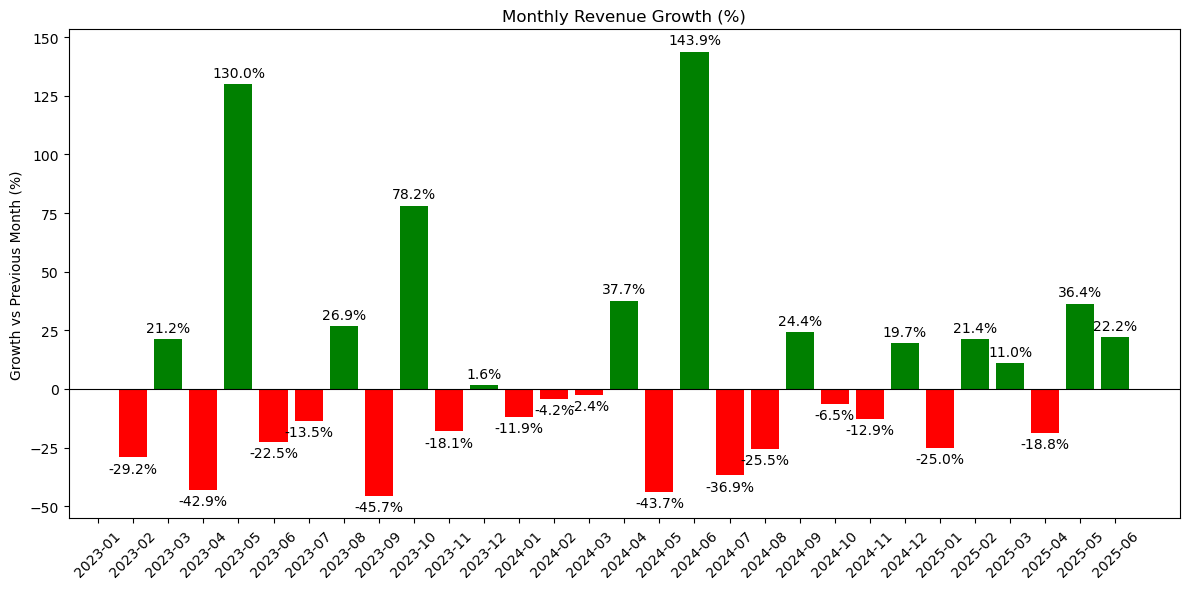

In [24]:
monthly_revenue = DecodeLabs_df.groupby(
    DecodeLabs_df['Date'].dt.to_period('M')
)['TotalPrice'].sum()

monthly_growth = monthly_revenue.pct_change() * 100

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    monthly_growth.index.astype(str),
    monthly_growth,
    color=['green' if x >= 0 else 'red' for x in monthly_growth.fillna(0)]
)

ax.bar_label(bars, fmt='%.1f%%', padding=3)

ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Monthly Revenue Growth (%)')
ax.set_ylabel('Growth vs Previous Month (%)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Histogram - Distribution of the data in Field with Numeric Values

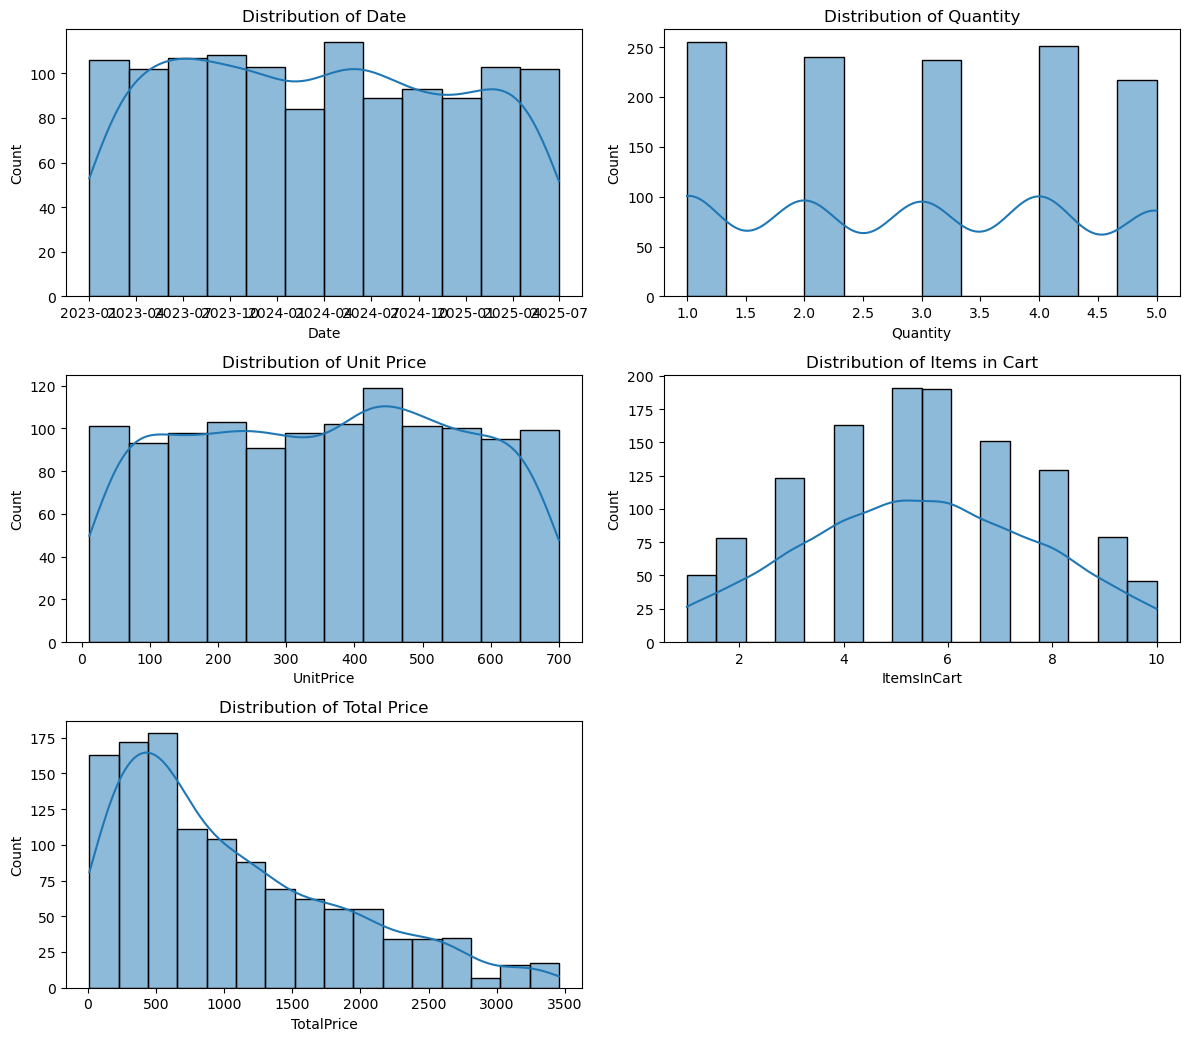

In [25]:

plt.figure(figsize=(12, 17))

plt.subplot(5, 2, 1)
sns.histplot(data=DecodeLabs_df, x='Date', kde=True)
plt.title('Distribution of Date')

plt.subplot(5, 2, 2)
sns.histplot(data=DecodeLabs_df, x='Quantity', kde=True)
plt.title('Distribution of Quantity')

plt.subplot(5, 2, 3)
sns.histplot(data=DecodeLabs_df, x='UnitPrice', kde=True)
plt.title('Distribution of Unit Price')

plt.subplot(5, 2, 4)
sns.histplot(data=DecodeLabs_df, x='ItemsInCart', kde=True)
plt.title('Distribution of Items in Cart')

plt.subplot(5, 2, 5)
sns.histplot(data=DecodeLabs_df, x='TotalPrice', kde=True)
plt.title('Distribution of Total Price')

plt.tight_layout()
plt.show()


# Descriptive Statistics

## Mean

In [26]:
DecodeLabs_df.select_dtypes(include='number').mean()

Quantity                   2.945833
UnitPrice                356.412750
ItemsInCart                5.485000
TotalPrice              1053.968300
Cumulative_Revenue    646186.468558
dtype: float64

## Median

In [27]:
DecodeLabs_df.select_dtypes(include='number').median()

Quantity                   3.000
UnitPrice                364.210
ItemsInCart                5.000
TotalPrice               823.615
Cumulative_Revenue    656277.925
dtype: float64

## Count

In [28]:
DecodeLabs_df.count()

OrderID               1200
Date                  1200
CustomerID            1200
Product               1200
Quantity              1200
UnitPrice             1200
ShippingAddress       1200
PaymentMethod         1200
OrderStatus           1200
TrackingNumber        1200
ItemsInCart           1200
CouponCode             891
ReferralSource        1200
TotalPrice            1200
Cumulative_Revenue    1200
dtype: int64

## Minimum values

In [29]:
DecodeLabs_df.select_dtypes(include='number').min()

Quantity                1.00
UnitPrice              11.39
ItemsInCart             1.00
TotalPrice             11.39
Cumulative_Revenue    410.60
dtype: float64

## Maximum values

In [30]:
DecodeLabs_df.select_dtypes(include='number').max()

Quantity                    5.00
UnitPrice                 699.93
ItemsInCart                10.00
TotalPrice               3456.40
Cumulative_Revenue    1264761.96
dtype: float64

## Standard Deviation

In [31]:
DecodeLabs_df.select_dtypes(include='number').std()

Quantity                   1.407557
UnitPrice                197.177146
ItemsInCart                2.281983
TotalPrice               819.856558
Cumulative_Revenue    362971.535111
dtype: float64

## Variance

In [32]:
DecodeLabs_df.select_dtypes(include='number').var()

Quantity              1.981217e+00
UnitPrice             3.887883e+04
ItemsInCart           5.207448e+00
TotalPrice            6.721648e+05
Cumulative_Revenue    1.317483e+11
dtype: float64

## Total Price Distribution Plot

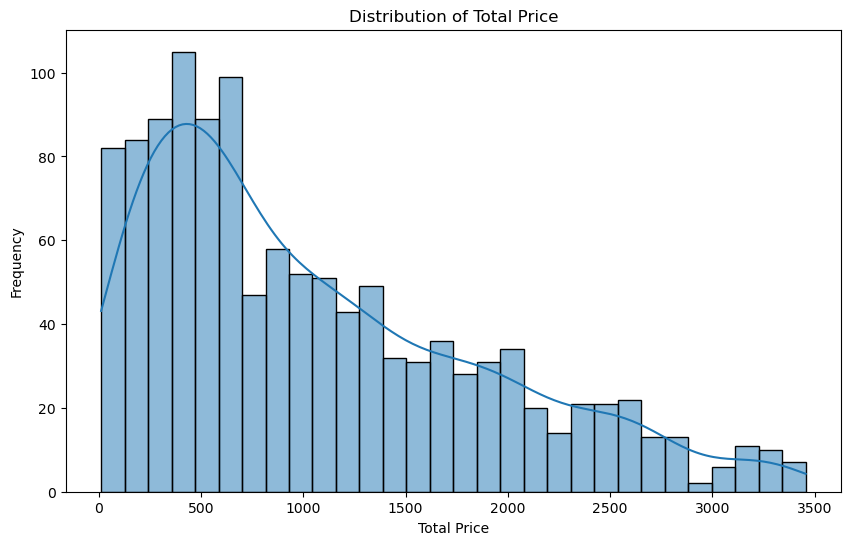

In [33]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# TotalPrice must be numeric and clean
DecodeLabs_df['TotalPrice'] = pd.to_numeric(DecodeLabs_df['TotalPrice'], errors='coerce')
plot_data = DecodeLabs_df['TotalPrice'].replace([float('inf'), float('-inf')], pd.NA).dropna()

# Distribution plot
plt.figure(figsize=(10, 6))
sns.histplot(plot_data, kde=True, bins=30)
plt.title('Distribution of Total Price')
plt.xlabel('Total Price')
plt.ylabel('Frequency')
plt.show()

## Total Price Density

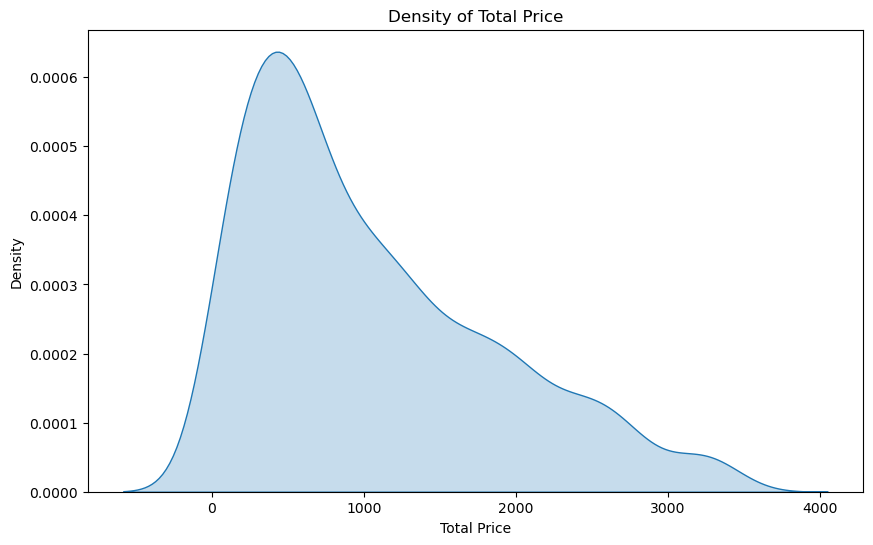

In [34]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

DecodeLabs_df['TotalPrice'] = pd.to_numeric(DecodeLabs_df['TotalPrice'], errors='coerce')
plot_data = DecodeLabs_df['TotalPrice'].replace([float('inf'), float('-inf')], pd.NA).dropna()

plt.figure(figsize=(10, 6))
sns.kdeplot(x=plot_data, fill=True)
plt.title('Density of Total Price')
plt.xlabel('Total Price')
plt.ylabel('Density')
plt.show()

## Frequency counts

In [35]:
DecodeLabs_df['Product'].value_counts()

Product
Printer    181
Tablet     179
Chair      178
Laptop     173
Desk       170
Monitor    163
Phone      156
Name: count, dtype: int64

## Percentage distribution

In [36]:
DecodeLabs_df['Product'].value_counts(normalize=True) * 100

Product
Printer    15.083333
Tablet     14.916667
Chair      14.833333
Laptop     14.416667
Desk       14.166667
Monitor    13.583333
Phone      13.000000
Name: proportion, dtype: float64

## Number of unique products

In [37]:
DecodeLabs_df['Product'].nunique()

7

## Bivariate Analysis – Identifying Relationships

## Categorical vs categorical variables
### Using cross-tabulation to investigate relationships between categories.

#### Analysis of Product by Order Status

In [38]:
pd.crosstab(
    DecodeLabs_df['Product'],
    DecodeLabs_df['OrderStatus']
)

OrderStatus,Cancelled,Delivered,Pending,Returned,Shipped
Product,,,,,
Chair,45,33,41,28,31
Desk,35,32,38,32,33
Laptop,35,40,30,39,29
Monitor,35,31,29,36,32
Phone,31,38,28,31,28
Printer,35,29,37,38,42
Tablet,34,28,34,43,40


### Analysis of Product by Order Status in Percentage

In [39]:
pd.crosstab(
    DecodeLabs_df['Product'],
    DecodeLabs_df['OrderStatus'],
    normalize='index'
).mul(100).round(1)

OrderStatus,Cancelled,Delivered,Pending,Returned,Shipped
Product,,,,,
Chair,25.3,18.5,23.0,15.7,17.4
Desk,20.6,18.8,22.4,18.8,19.4
Laptop,20.2,23.1,17.3,22.5,16.8
Monitor,21.5,19.0,17.8,22.1,19.6
Phone,19.9,24.4,17.9,19.9,17.9
Printer,19.3,16.0,20.4,21.0,23.2
Tablet,19.0,15.6,19.0,24.0,22.3


### Analysis of Product by Coupon Code

In [40]:
pd.crosstab(
    DecodeLabs_df['Product'],
    DecodeLabs_df['CouponCode']
)

CouponCode,FREESHIP,SAVE10,WINTER15
Product,,,
Chair,44,41,45
Desk,45,35,49
Laptop,45,42,40
Monitor,37,35,44
Phone,44,46,27
Printer,50,50,39
Tablet,48,37,48


### Analysis of Product by Referral Source

In [41]:
pd.crosstab(
    DecodeLabs_df['Product'],
    DecodeLabs_df['ReferralSource']
)

ReferralSource,Email,Facebook,Google,Instagram,Referral
Product,,,,,
Chair,41,37,28,41,31
Desk,29,32,39,41,29
Laptop,33,31,33,40,36
Monitor,32,37,26,39,29
Phone,34,24,39,26,33
Printer,41,36,41,31,32
Tablet,40,31,35,41,32


### Analysis of Product by Referral Source in Percentage

In [42]:
pd.crosstab(
    DecodeLabs_df['Product'],
    DecodeLabs_df['ReferralSource'],
    normalize='index'
).mul(100).round(1)

ReferralSource,Email,Facebook,Google,Instagram,Referral
Product,,,,,
Chair,23.0,20.8,15.7,23.0,17.4
Desk,17.1,18.8,22.9,24.1,17.1
Laptop,19.1,17.9,19.1,23.1,20.8
Monitor,19.6,22.7,16.0,23.9,17.8
Phone,21.8,15.4,25.0,16.7,21.2
Printer,22.7,19.9,22.7,17.1,17.7
Tablet,22.3,17.3,19.6,22.9,17.9


# Multivariate analysis – understanding multiple variables
### Multivariate analysis examines three or more variables simultaneously.


## Pair Plot

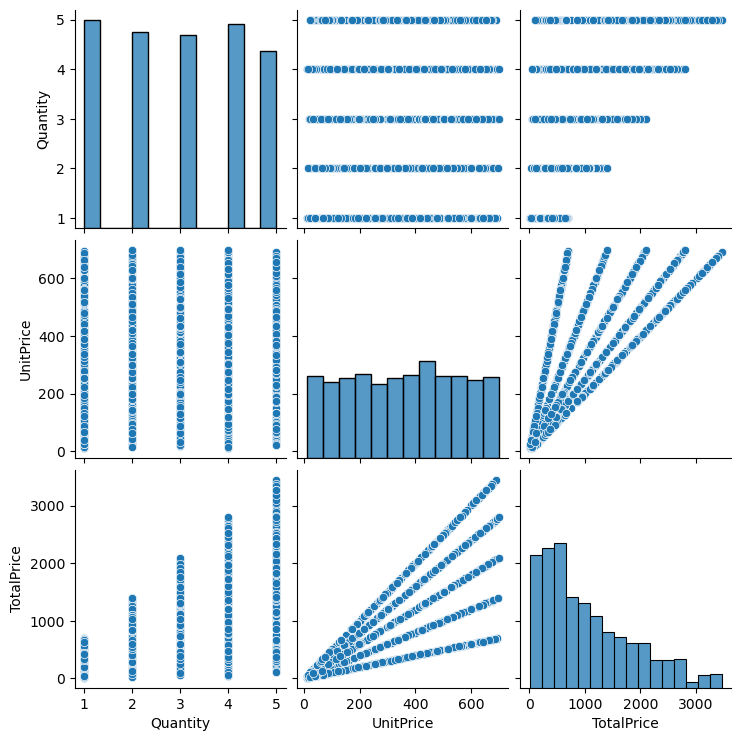

In [43]:
sns.pairplot(
    DecodeLabs_df,
    vars=['Quantity', 'UnitPrice', 'TotalPrice'],
    diag_kind='hist'
)

plt.show()

This helps you identify:
- Positive relationships.
- Negative relationships.
- Clusters.
- Potential outliers.
- Distribution patterns.

## Identifying Outliers - Outlier detection
Outliers are observations that are unusually high or low compared with the rest of the dataset.

They may indicate unusual customer behaviour, data-entry errors or exceptional transactions.

## Boxplot - Outlier Detection in Field / Column Values

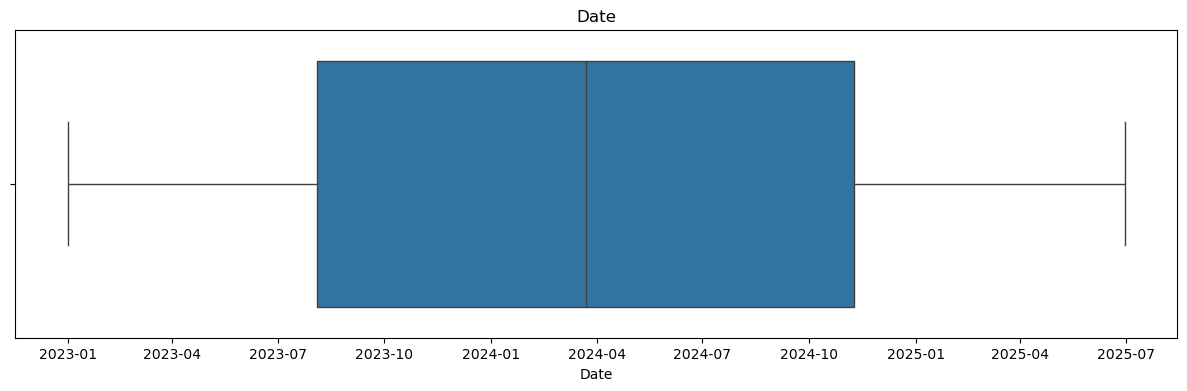

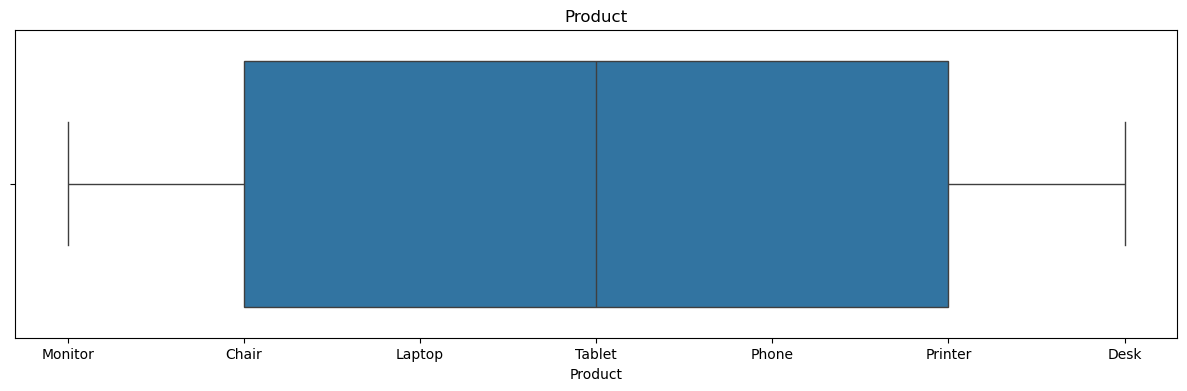

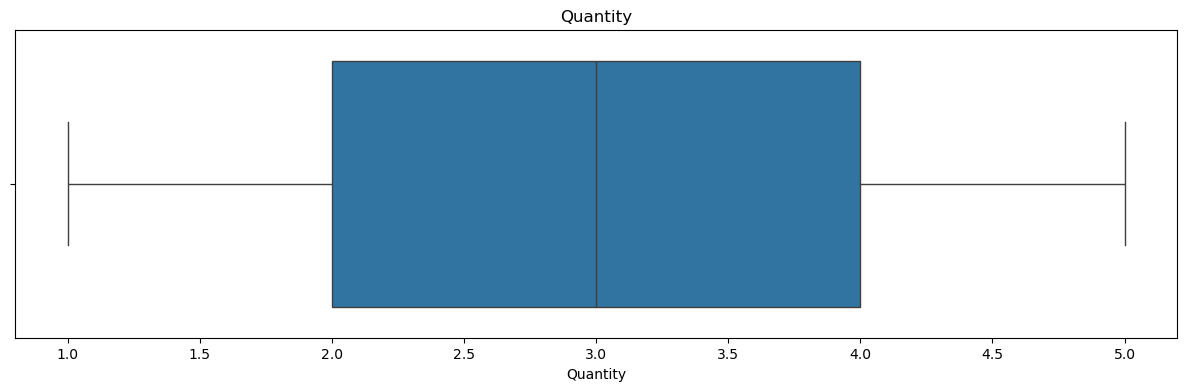

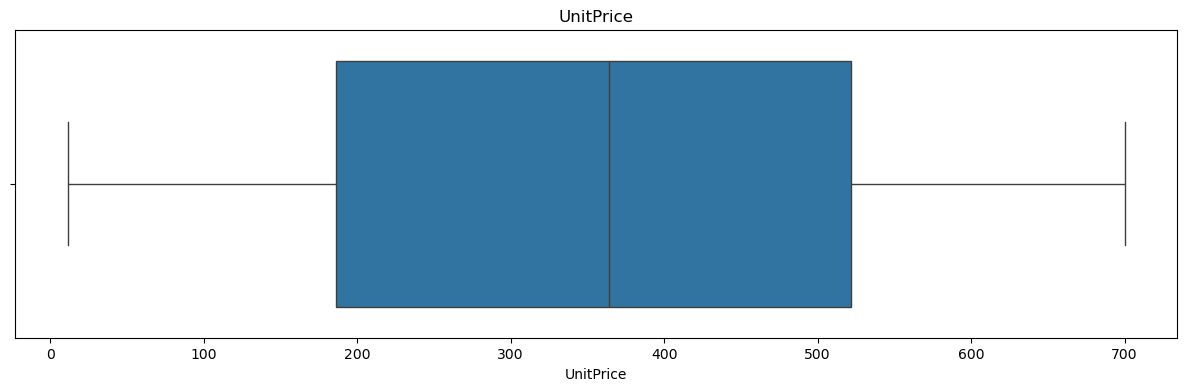

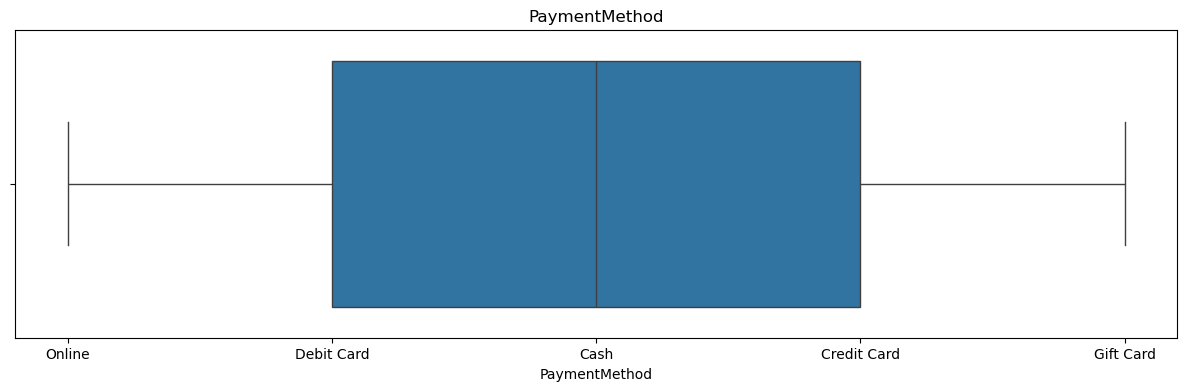

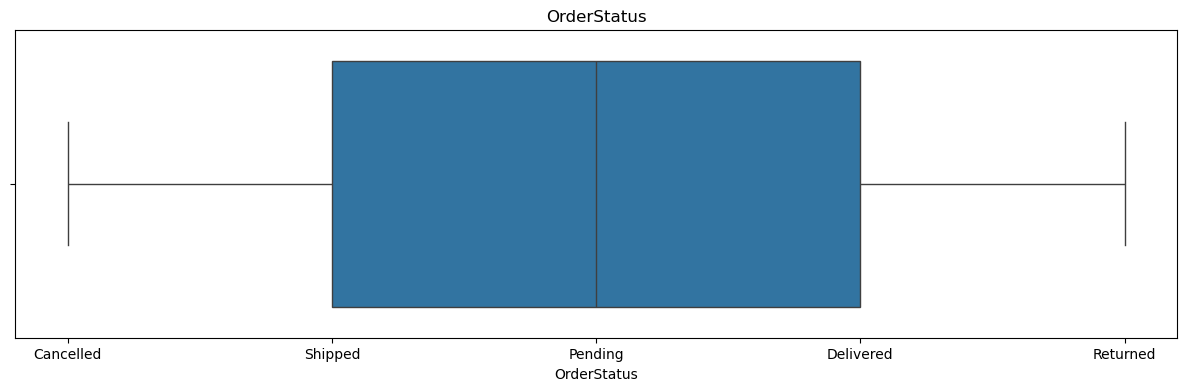

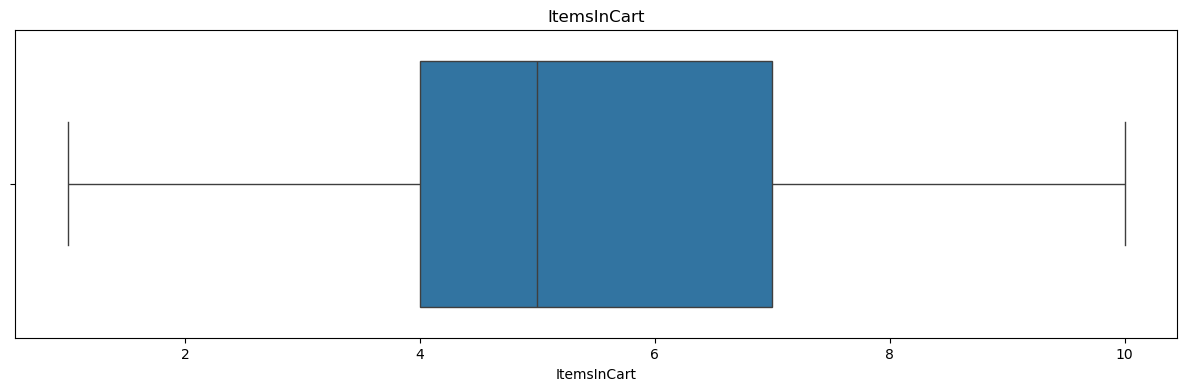

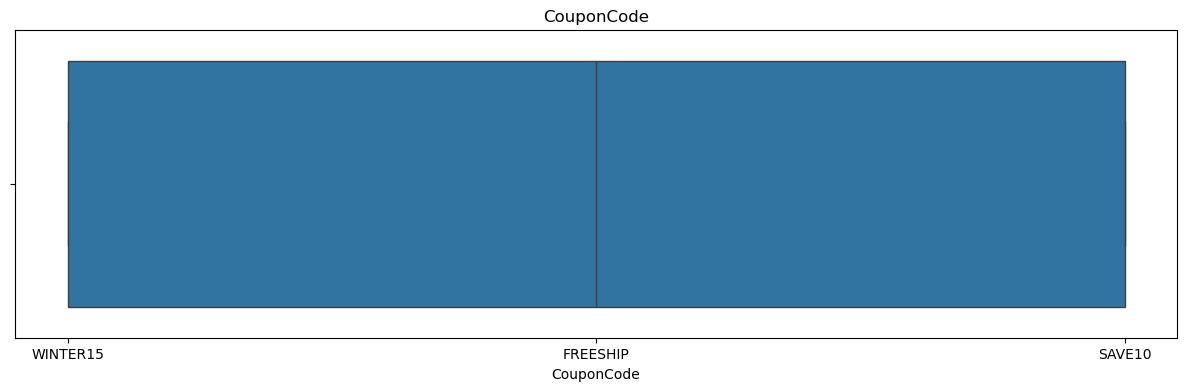

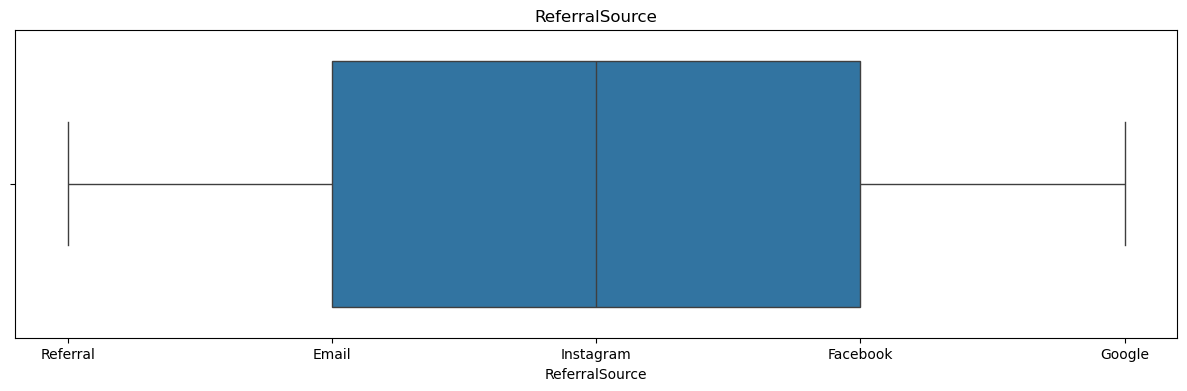

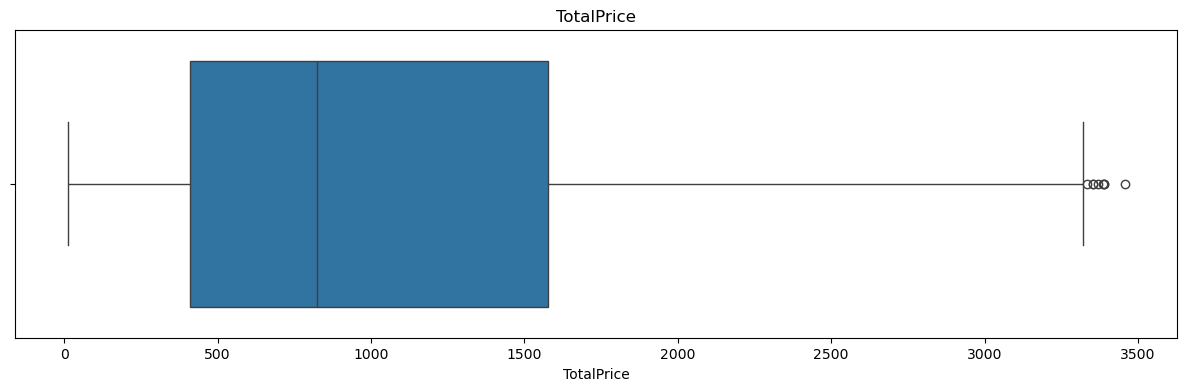

In [44]:
for column in ['Date', 'Product', 'Quantity', 'UnitPrice',
       'PaymentMethod', 'OrderStatus',
       'ItemsInCart', 'CouponCode', 'ReferralSource', 'TotalPrice']:
    plt.figure(figsize=(15, 4))
    sns.boxplot(data=DecodeLabs_df, x=column)
    plt.title(column)
    plt.show()

## Group By Analysis – Extracting Business Insights

### Product Performance Analysis

In [45]:
product_analysis = DecodeLabs_df.groupby('Product').agg(
    Total_Quantity=('Quantity', 'sum'),
    Average_Quantity=('Quantity', 'mean'),
    Total_Revenue=('TotalPrice', 'sum'),
    Average_Revenue=('TotalPrice', 'mean'),
    Average_UnitPrice=('UnitPrice', 'mean'),
    Transaction_Count=('Product', 'count')
).sort_values(
    by='Total_Revenue',
    ascending=False
)

print(product_analysis)

         Total_Quantity  Average_Quantity  Total_Revenue  Average_Revenue  \
Product                                                                     
Chair               562          3.157303      195620.11      1098.989382   
Printer             542          2.994475      195612.61      1080.732652   
Laptop              535          3.092486      192126.56      1110.558150   
Tablet              497          2.776536      186568.95      1042.284637   
Monitor             480          2.944785      175651.41      1077.616012   
Desk                508          2.988235      167459.93       985.058412   
Phone               411          2.634615      151722.39       972.579423   

         Average_UnitPrice  Transaction_Count  
Product                                        
Chair           355.660281                178  
Printer         351.714917                181  
Laptop          357.707052                173  
Tablet          367.679106                179  
Monitor         35

## B. Interquartile Range (IQR) - Outlier Detection

In [46]:
Q1 = DecodeLabs_df['TotalPrice'].quantile(0.25)
Q3 = DecodeLabs_df['TotalPrice'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = DecodeLabs_df[
    (DecodeLabs_df['TotalPrice'] < lower_limit) |
    (DecodeLabs_df['TotalPrice'] > upper_limit)
]

print('Number of outliers:', len(outliers))
print(outliers)

Number of outliers: 8
       OrderID       Date CustomerID  Product  Quantity  UnitPrice  \
83   ORD200328 2023-02-28     C18404   Tablet         5     674.04   
122  ORD200107 2023-03-27     C16775  Printer         5     670.75   
161  ORD200632 2023-05-02     C67260   Laptop         5     678.16   
220  ORD201122 2023-06-07     C38840  Monitor         5     678.19   
317  ORD200789 2023-08-17     C57276   Tablet         5     691.28   
418  ORD201065 2023-10-30     C47778  Printer         5     666.80   
456  ORD200469 2023-11-26     C13877    Chair         5     676.98   
747  ORD200326 2024-07-01     C65986   Laptop         5     670.48   

    ShippingAddress PaymentMethod OrderStatus TrackingNumber  ItemsInCart  \
83      546 Main St        Online   Cancelled    TRK89401624            7   
122     848 Main St     Gift Card     Shipped    TRK34392124            8   
161     463 Main St     Gift Card   Delivered    TRK38229104            7   
220     766 Main St        Online    Re